<a href="https://colab.research.google.com/github/YESENIA-AVILA/Modelado-y-simulaci-n-de-sistemas-mecatr-nicos/blob/main/AF_5__Simulaci%C3%B3n_de_un_sistema_a_partir_de_ecuaciones_de_Euler_Lagrange.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#A.F.No.5: Simulación de un sistema a partir de ecuaciones de Euler-Lagrange
#Realizar la simulación en pyhton a partir de los resultados de ecuación característica
#del modelo dinámico del sistema péndulo-robot a partir del formalismo de Euler-Lagrange.

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

Parámetros del sistema

In [ ]:
Ir = 0.16
m = 5.0
g = 9.81
lc = 0.01
b = 0.14
fc = 0.45

Torque aplicado por el motor

In [ ]:
def tau(t):
    return 1.5 * np.sin(t)

Modelo dinámico

In [ ]:
def f(t, x):

    # Variables de estado
    q = x[0]
    qp = x[1]

    # Fricción de Coulomb suavizada
    friccion_coulomb = fc * np.tanh(100 * qp)

    # Ecuación dinámica
    qpp = (tau(t) - m*g*lc*np.sin(q)
           - b*qp - friccion_coulomb) / Ir

    # Derivadas de los estados
    dxdt = [qp, qpp]

    return dxdt

Parámetros de simulación

In [ ]:
ti = 0.0
tf = 10.0
h = 0.0025

ts = np.linspace(ti, tf, int((tf-ti)/h) + 1)

# Condiciones iniciales
q0 = 0.0
qp0 = 0.0

x0 = [q0, qp0]

Resolución de la ec. diferencial

In [ ]:
sol = solve_ivp(
    f,
    [ti, tf],
    x0,
    t_eval=ts,
    max_step=h,
    rtol=1e-6,
    atol=1e-8
)

if not sol.success:
    raise RuntimeError(sol.message)

# Extracción de resultados
t = sol.t
posicion = sol.y[0]
velocidad = sol.y[1]

# Conversión a grados
posicion_grados = np.rad2deg(posicion)
velocidad_grados = np.rad2deg(velocidad)

Gráficas de resultado

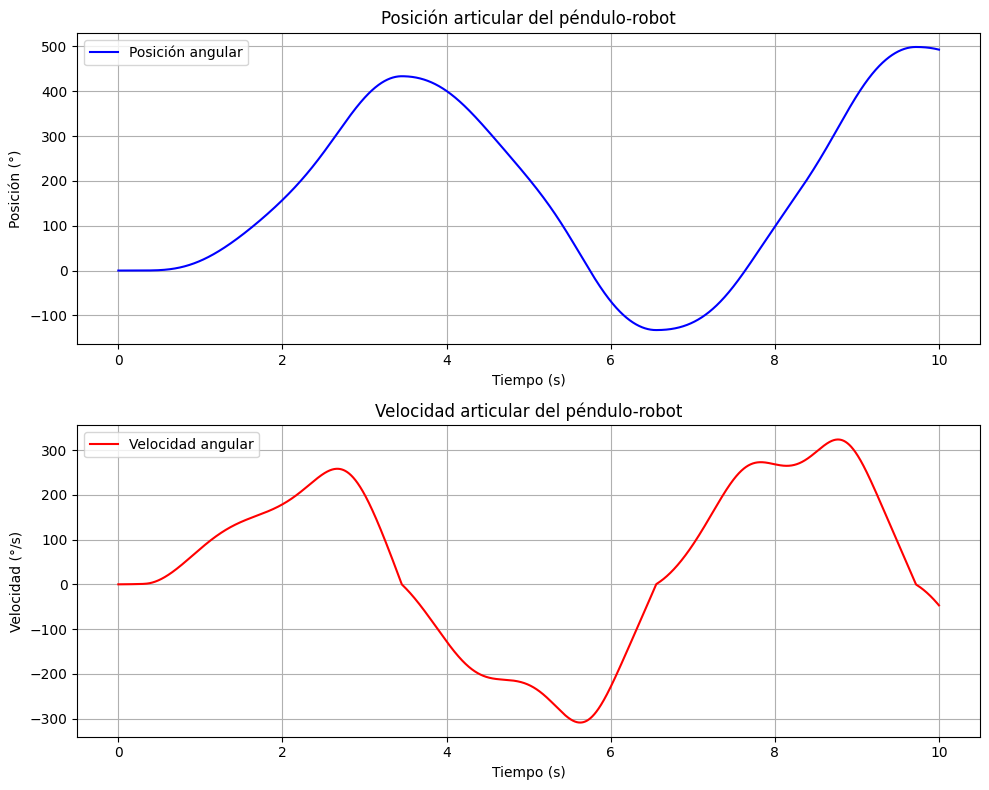

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# Posición angular
ax1.plot(t, posicion_grados, 'b-', label='Posición angular')
ax1.set_xlabel('Tiempo (s)')
ax1.set_ylabel('Posición (°)')
ax1.set_title('Posición articular del péndulo-robot')
ax1.grid(True)
ax1.legend()

# Velocidad angular
ax2.plot(t, velocidad_grados, 'r-', label='Velocidad angular')
ax2.set_xlabel('Tiempo (s)')
ax2.set_ylabel('Velocidad (°/s)')
ax2.set_title('Velocidad articular del péndulo-robot')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()